# BT4012 Fraud Analytics Group 14: Classical models (LR, RF, XGBoost)

Trains logistic regression, random forest and XGBoost on the engineered tabular features
(`data/processed/tabular_features_folds/split_<s>`), one of each per walk-forward fold in
`data/splits/temporal_splits.csv`, with loss reweighting. Tabular only — text is Person
2's own step 7 ("rerun Person 1's best model with text added").

No hyperparameter tuning here (fixed, documented defaults) — tuning is a separate, later
step. Predictions and per-fold metrics are written in the same schema as Person 4's
`results/rgcn_predictions.csv` / `results/rgcn_results.csv`, so they can be combined with
one `pd.concat` later.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 20, "display.width", 200)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RESULTS_DIR = ROOT / "results"
SEED = 0

splits = pd.read_csv(ROOT / "data" / "splits" / "temporal_splits.csv")
SPLIT_IDS = sorted(splits["split"].unique())
TEST_YEARS = {s: int(splits.loc[(splits["split"] == s) & (splits["role"] == "test"), "Year"].iloc[0]) for s in SPLIT_IDS}
print("test year per split:", TEST_YEARS)

test year per split: {np.int64(0): 2019, np.int64(1): 2020, np.int64(2): 2021, np.int64(3): 2022}


## Data loading

Each fold's engineered table is already imputed and scaled (`src/build_tabular_features.py`),
so it's used as-is — no further preprocessing needed here.

In [2]:
def load_fold(s: int) -> pd.DataFrame:
    tabular = pd.read_parquet(ROOT / "data" / "processed" / "tabular_features_folds" / f"split_{s}")
    rows = splits.loc[splits["split"] == s, ["nodeID", "Year", "Label", "role"]]
    df = rows.merge(tabular, on=["nodeID", "Year"], how="left", validate="one_to_one")
    assert df.drop(columns=["nodeID", "Year", "Label", "role"]).notna().all(axis=None), f"split {s}: unmatched rows after merge"
    return df

FEATURE_COLS = [c for c in load_fold(0).columns if c not in ("nodeID", "Year", "Label", "role")]
print(f"{len(FEATURE_COLS):,} feature columns")

1,238 feature columns


## Models and reweighting

- **Logistic regression**: `class_weight="balanced"` — sklearn computes this from
  whatever `y` is passed to `.fit`, which is only that fold's train rows below.
- **Random forest**: same, `class_weight="balanced"`.
- **XGBoost**: no "balanced" shortcut, so `scale_pos_weight` is computed explicitly as
  `(train negatives) / (train positives)` for that fold.

Fixed seed, fixed (untuned) hyperparameters — chosen to be reasonable defaults, not the
result of a search. Tuning is a separate step.

In [3]:
def make_models(y_train: np.ndarray) -> dict:
    neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
    return {
        "logreg": LogisticRegression(class_weight="balanced", max_iter=20000, random_state=SEED),
        "rf": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
        "xgb": XGBClassifier(n_estimators=300, scale_pos_weight=neg / pos, eval_metric="logloss",
                              random_state=SEED, n_jobs=-1),
    }

## Walk-forward experiments

One fit per model per fold, train rows only. Scores are predicted for every row (train
and test) so the predictions file can support a later misclassification analysis on
training rows too, not just the test year.

In [4]:
pred_rows, result_rows = [], []

for s in SPLIT_IDS:
    df = load_fold(s)
    train = (df["role"] == "train").to_numpy()
    X_train, y_train = df.loc[train, FEATURE_COLS], df.loc[train, "Label"].to_numpy()
    X_all = df[FEATURE_COLS]

    models = make_models(y_train)
    for name, model in models.items():
        start = time.time()
        model.fit(X_train, y_train)
        elapsed = time.time() - start
        scores = model.predict_proba(X_all)[:, 1]

        pred_rows.append(pd.DataFrame({
            "nodeID": df["nodeID"], "Year": df["Year"], "Label": df["Label"],
            "model": name, "score": scores,
        }))

        test = df["Year"].to_numpy() == TEST_YEARS[s]
        result_rows.append({
            "model": name, "split": s, "test_year": TEST_YEARS[s],
            "best_epoch": np.nan, "val_auc": np.nan,
            "test_auc": roc_auc_score(df.loc[test, "Label"], scores[test]),
            "test_pr_auc": average_precision_score(df.loc[test, "Label"], scores[test]),
            "test_fraud_rate": df.loc[test, "Label"].mean(),
            "seconds": round(elapsed, 4), "peak_gpu_gb": np.nan,
        })
        print(f"split {s} ({TEST_YEARS[s]})  {name:7s}  {elapsed:.1f}s")

preds_df = pd.concat(pred_rows, ignore_index=True)
res = pd.DataFrame(result_rows)
res

split 0 (2019)  logreg   49.8s


split 0 (2019)  rf       4.8s


split 0 (2019)  xgb      11.5s


split 1 (2020)  logreg   62.9s


split 1 (2020)  rf       6.6s


split 1 (2020)  xgb      13.6s


... (3 outputs left out)

split 3 (2022)  logreg   123.4s


split 3 (2022)  rf       10.6s


split 3 (2022)  xgb      17.9s


,model,split,test_year,best_epoch,val_auc,test_auc,test_pr_auc,test_fraud_rate,seconds,peak_gpu_gb
0,logreg,0,2019,NaN,NaN,0.590647,0.076392,0.056094,49.8108,NaN
1,rf,0,2019,NaN,NaN,0.850393,0.233711,0.056094,4.8398,NaN
2,xgb,0,2019,NaN,NaN,0.868928,0.368456,0.056094,11.4935,NaN
3,logreg,1,2020,NaN,NaN,0.675963,0.099191,0.048489,62.9252,NaN
4,rf,1,2020,NaN,NaN,0.826495,0.218573,0.048489,6.5942,NaN
5,xgb,1,2020,NaN,NaN,0.848089,0.365448,0.048489,13.6035,NaN
6,logreg,2,2021,NaN,NaN,0.701531,0.118903,0.038373,108.0624,NaN
7,rf,2,2021,NaN,NaN,0.811633,0.145242,0.038373,8.4209,NaN
8,xgb,2,2021,NaN,NaN,0.847564,0.288344,0.038373,15.6338,NaN
9,logreg,3,2022,NaN,NaN,0.824816,0.127184,0.023967,123.4135,NaN


In [5]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
preds_df.to_csv(RESULTS_DIR / "classical_predictions.csv", index=False)
res.to_csv(RESULTS_DIR / "classical_results.csv", index=False)

rgcn_cols = pd.read_csv(RESULTS_DIR / "rgcn_results.csv", nrows=0).columns.tolist()
assert list(res.columns) == rgcn_cols, "classical_results.csv columns don't match rgcn_results.csv"
print(f"PASS: columns match rgcn_results.csv exactly — a pd.concat of the two will just work")
print(f"wrote {len(preds_df):,} prediction rows and {len(res)} result rows to results/")

PASS: columns match rgcn_results.csv exactly — a pd.concat of the two will just work
wrote 316,359 prediction rows and 12 result rows to results/


## Visualising the metrics

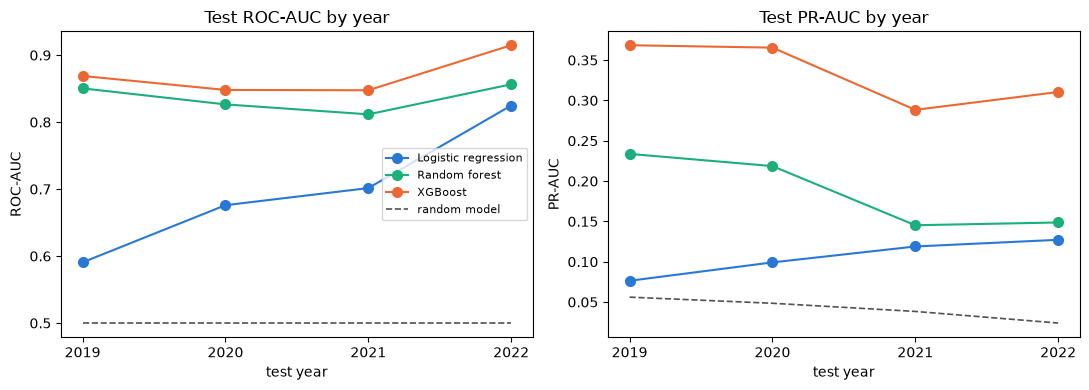

In [6]:
MODELS = ["logreg", "rf", "xgb"]
NAMES = {"logreg": "Logistic regression", "rf": "Random forest", "xgb": "XGBoost"}
COLORS = {"logreg": "#2a78d6", "rf": "#1baf7a", "xgb": "#eb6834"}

def subset(model, yr):
    return preds_df[(preds_df["model"] == model) & (preds_df["Year"] == yr)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in [(axes[0], "test_auc", "ROC-AUC"), (axes[1], "test_pr_auc", "PR-AUC")]:
    for m in MODELS:
        d = res[res["model"] == m].sort_values("test_year")
        ax.plot(d["test_year"], d[metric], marker="o", ms=7, color=COLORS[m], label=NAMES[m])
    rate = res[res["model"] == "logreg"].sort_values("test_year")
    baseline = [0.5] * len(rate) if metric == "test_auc" else rate["test_fraud_rate"]
    ax.plot(rate["test_year"], baseline, ls="--", lw=1.2, color="#52514e", label="random model")
    ax.set(title=f"Test {title} by year", xlabel="test year", ylabel=title, xticks=sorted(TEST_YEARS.values()))
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

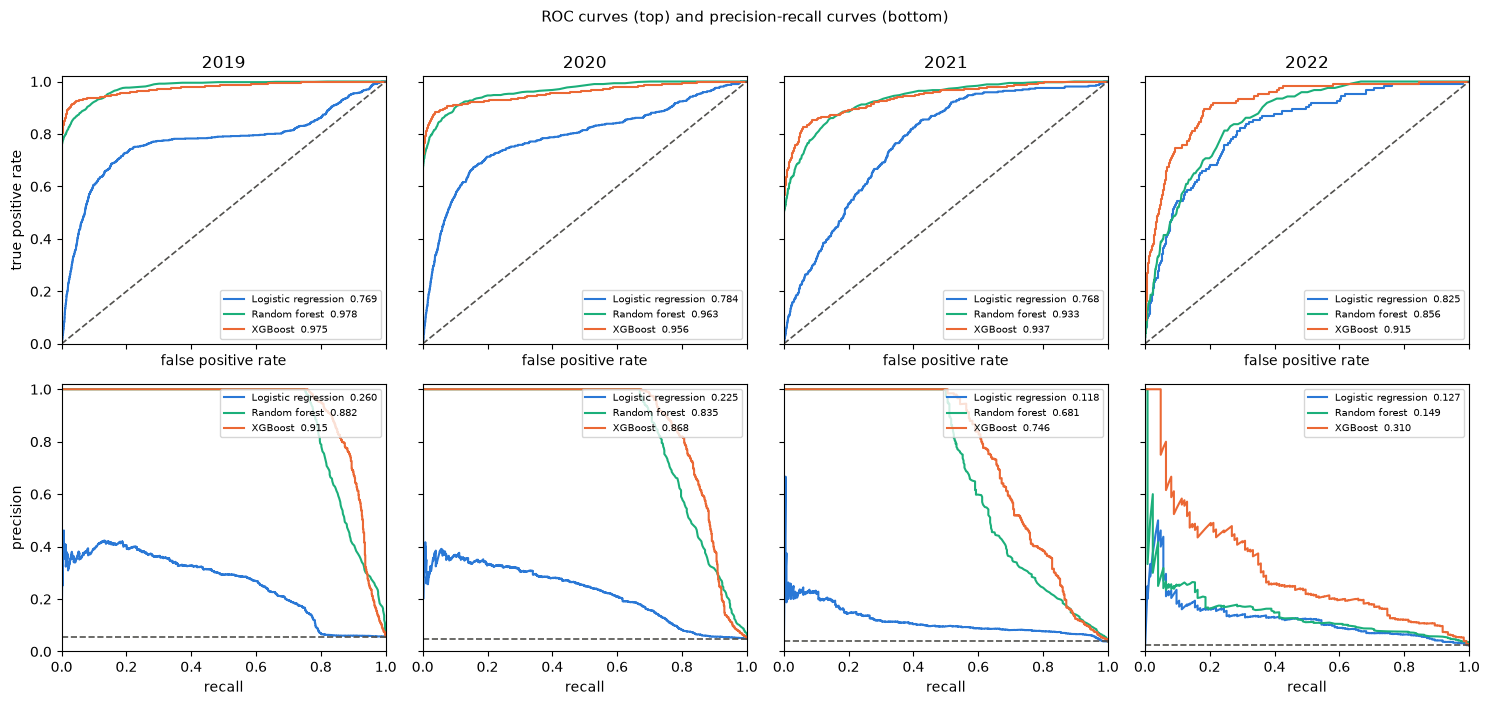

In [7]:
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 7), sharex=True, sharey="row")
for col, yr in enumerate(sorted(TEST_YEARS.values())):
    roc_ax, pr_ax = axes[0, col], axes[1, col]
    for m in MODELS:
        g = subset(m, yr)
        fpr, tpr, _ = roc_curve(g["Label"], g["score"])
        prec, rec, _ = precision_recall_curve(g["Label"], g["score"])
        auc, ap = roc_auc_score(g["Label"], g["score"]), average_precision_score(g["Label"], g["score"])
        roc_ax.plot(fpr, tpr, color=COLORS[m], label=f"{NAMES[m]}  {auc:.3f}")
        pr_ax.plot(rec, prec, color=COLORS[m], label=f"{NAMES[m]}  {ap:.3f}")
    rate_yr = g["Label"].mean()
    roc_ax.plot([0, 1], [0, 1], ls="--", lw=1.2, color="#52514e")
    pr_ax.plot([0, 1], [rate_yr, rate_yr], ls="--", lw=1.2, color="#52514e")
    roc_ax.set(title=str(yr), xlim=(0, 1), ylim=(0, 1.02), xlabel="false positive rate")
    pr_ax.set(xlabel="recall", ylim=(0, 1.02))
    roc_ax.legend(fontsize=7, loc="lower right")
    pr_ax.legend(fontsize=7, loc="upper right")
axes[0, 0].set_ylabel("true positive rate")
axes[1, 0].set_ylabel("precision")
fig.suptitle("ROC curves (top) and precision-recall curves (bottom)", y=1.0, fontsize=11)
fig.tight_layout()
plt.show()

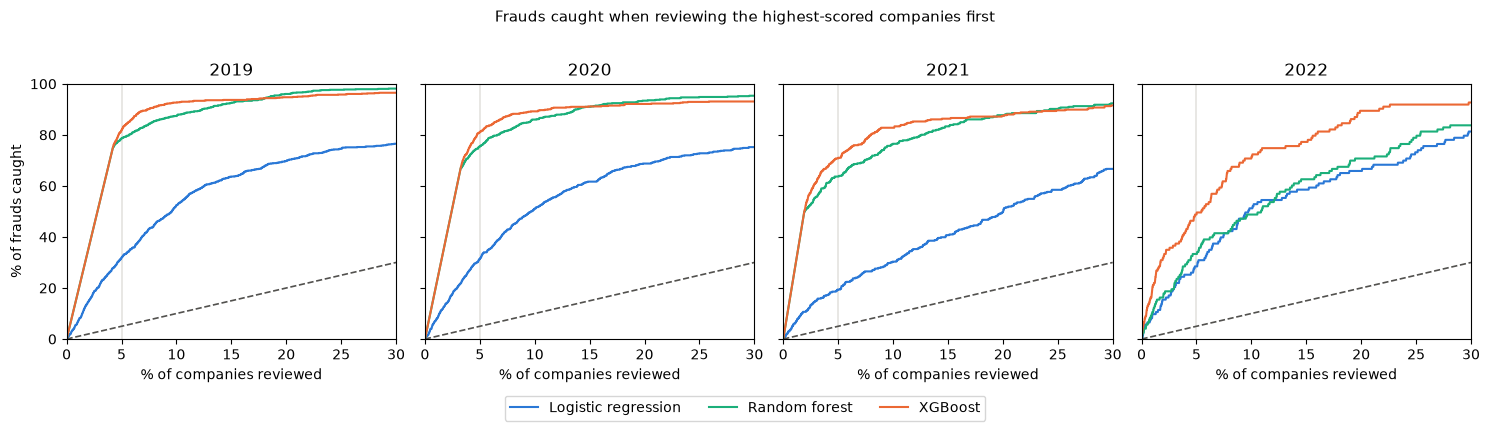

In [8]:
fig, axes = plt.subplots(1, len(TEST_YEARS), figsize=(15, 3.8), sharey=True)
for ax, yr in zip(axes, sorted(TEST_YEARS.values())):
    for m in MODELS:
        y_sorted = subset(m, yr).sort_values("score", ascending=False)["Label"].to_numpy()
        reviewed = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
        ax.plot(reviewed * 100, np.cumsum(y_sorted) / y_sorted.sum() * 100, color=COLORS[m], label=NAMES[m])
    ax.plot([0, 30], [0, 30], ls="--", lw=1.2, color="#52514e")
    ax.axvline(5, color="#e4e3df", lw=1.2, zorder=0)
    ax.set(title=str(yr), xlim=(0, 30), ylim=(0, 100), xlabel="% of companies reviewed")
axes[0].set_ylabel("% of frauds caught")
handles, names = axes[0].get_legend_handles_labels()
fig.suptitle("Frauds caught when reviewing the highest-scored companies first", y=1.02, fontsize=11)
fig.tight_layout()
fig.legend(handles, names, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.08))
plt.show()

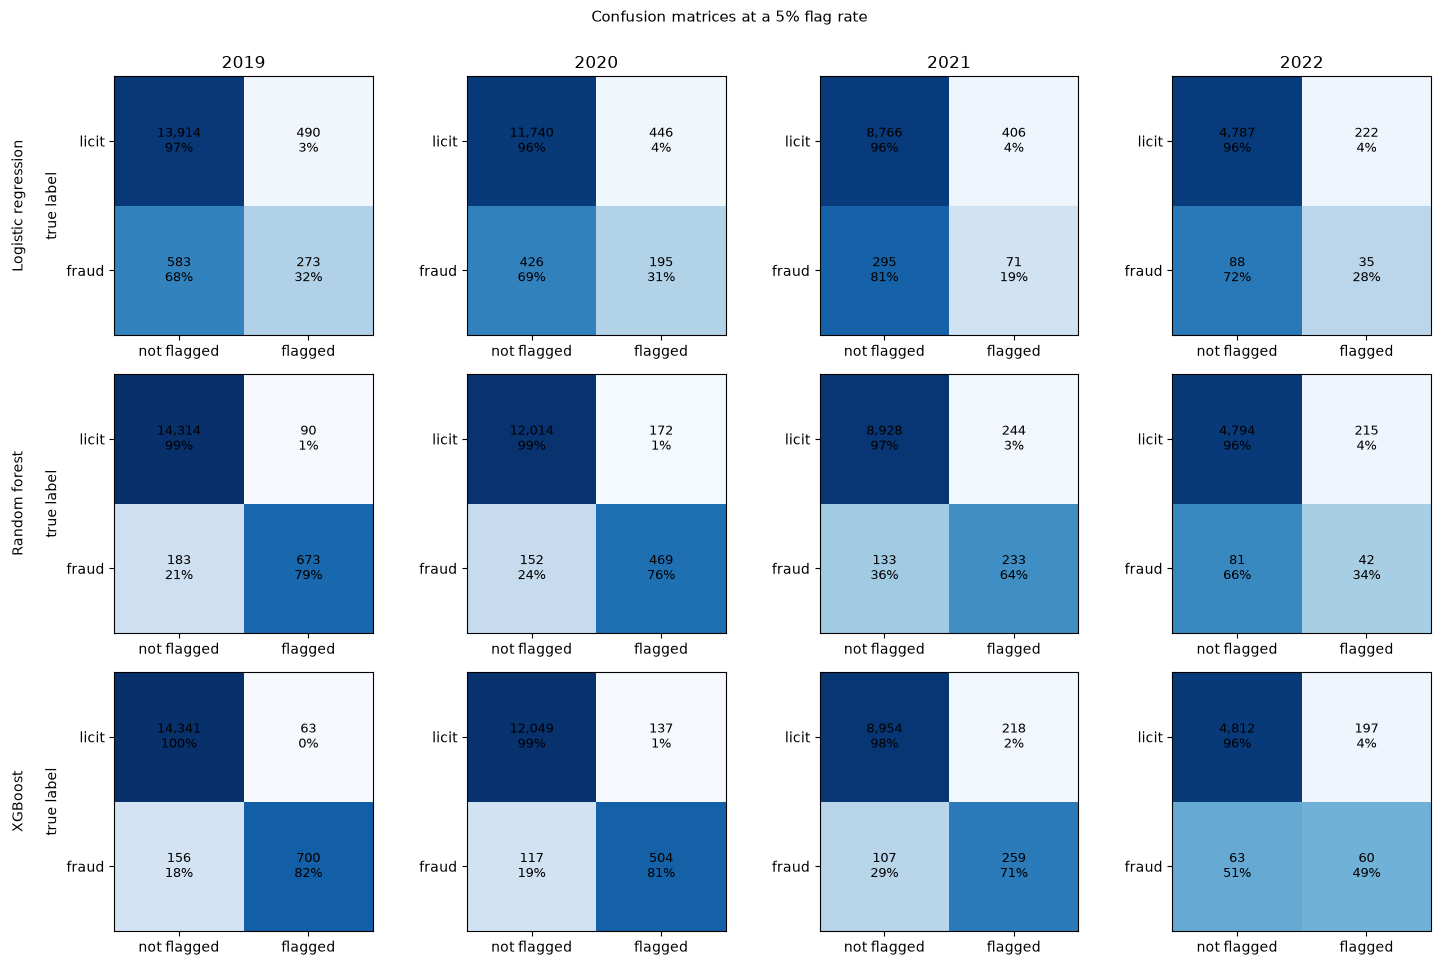

In [9]:
FLAG_SHARE = 0.05
fig, axes = plt.subplots(len(MODELS), len(TEST_YEARS), figsize=(15, 3.2 * len(MODELS)))
for r, m in enumerate(MODELS):
    for c, yr in enumerate(sorted(TEST_YEARS.values())):
        g = subset(m, yr)
        n_flag = int(np.ceil(FLAG_SHARE * len(g)))
        flagged = np.zeros(len(g), dtype=int)
        flagged[np.argsort(-g["score"].to_numpy())[:n_flag]] = 1
        cm = confusion_matrix(g["Label"], flagged, labels=[0, 1])
        share = cm / cm.sum(axis=1, keepdims=True)
        ax = axes[r, c]
        ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.0%}", ha="center", va="center", fontsize=9)
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["not flagged", "flagged"], yticklabels=["licit", "fraud"])
        if r == 0:
            ax.set_title(str(yr))
        if c == 0:
            ax.set_ylabel(f"{NAMES[m]}\n\ntrue label")
fig.suptitle(f"Confusion matrices at a {FLAG_SHARE:.0%} flag rate", y=1.0, fontsize=11)
fig.tight_layout()
plt.show()

## LR dimensionality check

Resolves the PCA question deferred in step 4: were the 1,238 engineered columns
(including correlated-but-under-threshold features and YoY deltas) too much for logistic
regression even with its default L2 regularization? A concrete sign would be
wildly large or unstable coefficient magnitudes across folds.

In [10]:
coef_summary = []
for s in SPLIT_IDS:
    df = load_fold(s)
    train = (df["role"] == "train").to_numpy()
    model = LogisticRegression(class_weight="balanced", max_iter=20000, random_state=SEED)
    model.fit(df.loc[train, FEATURE_COLS], df.loc[train, "Label"])
    coef_summary.append({
        "split": s, "max_abs_coef": np.abs(model.coef_).max(),
        "median_abs_coef": np.median(np.abs(model.coef_)),
        "n_coef_over_10": int((np.abs(model.coef_) > 10).sum()),
    })
coef_df = pd.DataFrame(coef_summary)
print(coef_df.to_string(index=False))
if (coef_df["max_abs_coef"] > 20).any():
    print("\nSome coefficients are large and unstable — clear sign step 7 should revisit PCA/stronger regularization.")
else:
    print("\nCoefficients aren't exploding, so this isn't classic multicollinearity blow-up. But LR's test AUC "
          "(0.59-0.83 across folds) is well below RF (0.81-0.86) and XGBoost (0.85-0.91) even fully converged — "
          "a real performance gap, not a convergence artifact. Worth trying stronger regularization, feature "
          "selection, or PCA in step 7 to see if LR can close some of that gap, even though coefficients alone "
          "don't show the instability PCA would be fixing.")

 split  max_abs_coef  median_abs_coef  n_coef_over_10
     0      2.523794         0.094076               0
     1      1.949808         0.079586               0
     2      2.253697         0.077201               0
     3      2.838978         0.068998               0

Coefficients aren't exploding, so this isn't classic multicollinearity blow-up. But LR's test AUC (0.59-0.83 across folds) is well below RF (0.81-0.86) and XGBoost (0.85-0.91) even fully converged — a real performance gap, not a convergence artifact. Worth trying stronger regularization, feature selection, or PCA in step 7 to see if LR can close some of that gap, even though coefficients alone don't show the instability PCA would be fixing.


## Verification: reweighting really used only that fold's training rows

In [11]:
for s in SPLIT_IDS:
    df = load_fold(s)
    train = (df["role"] == "train").to_numpy()
    y_train_only = df.loc[train, "Label"].to_numpy()
    y_all = df["Label"].to_numpy()  # includes test rows — must NOT match, or something leaked

    train_only_weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train_only)
    full_fold_weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_all)
    neg, pos = int((y_train_only == 0).sum()), int((y_train_only == 1).sum())
    scale_pos_weight = neg / pos

    assert not np.allclose(train_only_weights, full_fold_weights), (
        f"split {s}: train-only and full-fold class weights are identical — "
        "this would only happen by coincidence, check load_fold()"
    )
    print(f"split {s}: train-only -> neg={neg:,} pos={pos:,}  "
          f"balanced weights={np.round(train_only_weights, 4)}  scale_pos_weight={scale_pos_weight:.4f}  "
          f"(full-fold weights would be {np.round(full_fold_weights, 4)} — different, confirming train/test aren't mixed)")

print("\nPASS: make_models(y_train) in the training loop above only ever receives this same "
      "train-only y, by construction — these are the exact weights it used.")

split 0: train-only -> neg=14,847 pos=832  balanced weights=[0.528  9.4225]  scale_pos_weight=17.8450  (full-fold weights would be [0.5283 9.3184] — different, confirming train/test aren't mixed)
split 1: train-only -> neg=18,448 pos=1,046  balanced weights=[0.5283 9.3184]  scale_pos_weight=17.6367  (full-fold weights would be [0.5278 9.4824] — different, confirming train/test aren't mixed)


split 2: train-only -> neg=22,510 pos=1,253  balanced weights=[0.5278 9.4824]  scale_pos_weight=17.9649  (full-fold weights would be [0.5265 9.9345] — different, confirming train/test aren't mixed)


split 3: train-only -> neg=27,096 pos=1,436  balanced weights=[0.5265 9.9345]  scale_pos_weight=18.8691  (full-fold weights would be [ 0.5243 10.7967] — different, confirming train/test aren't mixed)

PASS: make_models(y_train) in the training loop above only ever receives this same train-only y, by construction — these are the exact weights it used.
